# Aula 6 · Imputação e Normalização de Dados

[Roteiro da aula](https://oandrefonseca.github.io/data-science/aulas/06-imputacao-normalizacao-dados.html).

## Resumo

- **Imputação.** Primeiro, descubro o que a lacuna significa. O andar de uma casa é uma ausência estrutural, pois esse atributo se aplica a apartamentos. Quando falta um dado que deveria existir, posso tentar estimá-lo pela média, mediana, moda ou por uma estatística do grupo. Uma coluna indicadora registra as posições imputadas.

- **Escalonamento.** Coloco variáveis como área, aluguel e número de quartos em escalas comparáveis. O StandardScaler usa média e desvio-padrão, o RobustScaler usa mediana e intervalo interquartil, e o MinMaxScaler usa mínimo e máximo. Os três preservam a forma e a assimetria da distribuição. Um extremo pode comprimir os demais valores no Min-Max.

- **Transformações.** Uma função não linear pode comprimir a cauda e reduzir a assimetria. Log e Box-Cox exigem valores positivos. `log1p` é usado para dados com zero ou positivos e Yeo-Johnson, que também aceita negativos. Na hora de comunicar resultados, a unidade original costuma ser mais fácil de interpretar do que as outras.

## 1. Preparar e diagnosticar a base

Padronizo os nomes das colunas e removo duplicatas. Conforme a regra, a lacuna em `floor` identifica casas e fica registrada no tipo de imóvel. A tabela ajuda a distinguir esse caso das lacunas em condomínio e vagas.

In [3]:
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

nome_arquivo = "imoveis_sao_paulo.csv"
uploaded = files.upload()
if nome_arquivo not in uploaded:
    raise FileNotFoundError(f"Execute a célula novamente e selecione {nome_arquivo}.")

dados = pd.read_csv(BytesIO(uploaded[nome_arquivo]))
dados.columns = (
    dados.columns.str.replace(r"\s*\(R\$\)$", "", regex=True)
    .str.strip()
    .str.replace(" ", "_")
)
dados = dados.drop_duplicates().reset_index(drop=True)
dados["property_type"] = np.where(dados["floor"].isna(), "casa", "apartamento")

display(dados[["hoa", "parking_spaces", "floor"]].isna().mean().mul(100)
        .round(2).rename("Ausentes (%)").to_frame())
display(dados.groupby("property_type")["floor"]
        .agg(imoveis="size", proporcao_sem_andar=lambda valores: valores.isna().mean()))

Saving imoveis_sao_paulo.csv to imoveis_sao_paulo.csv


,Ausentes (%)
hoa,1.72
parking_spaces,1.01
floor,15.00


,imoveis,proporcao_sem_andar
property_type,,
apartamento,25024,0.0
casa,4415,1.0


## 2. Comparar estratégias de imputação

Para saber quanto a imputação erra, simulo lacunas em valores que são conhecidos. O sorteio usa uma semente fixa e independe do valor apagado, como no cenário MCAR. Calculo o MAE, ou erro absoluto médio, apenas nas posições apagadas. Dessa forma, os valores preservados ficam fora da conta.

O MAE avalia a precisão neste experimento, só que na base real, se a chance de faltar um aluguel depender do seu valor, o resultado da simulação pode deixar de representar o desempenho da imputação.

In [6]:
gabarito = dados.dropna(subset=["hoa", "parking_spaces"]).reset_index(drop=True)
simulado = gabarito.copy()
rng = np.random.default_rng(42)

for coluna, proporcao in {"rooms": 0.10, "rent_amount": 0.15, "furniture": 0.08}.items():
    simulado[coluna] = gabarito[coluna].mask(rng.random(len(gabarito)) < proporcao)

def mediana_por_grupo(base, coluna, grupos):
    valores = base[coluna]
    medianas = base.groupby(grupos)[coluna].transform("median")
    return valores.fillna(medianas).fillna(valores.median())

def mae_nas_lacunas(coluna, estimativas):
    apagados = simulado[coluna].isna() & gabarito[coluna].notna()
    erros = (gabarito.loc[apagados, coluna] - estimativas.loc[apagados]).abs()
    return erros.mean()

aluguel = simulado["rent_amount"]
metodos = {
    "Média": aluguel.fillna(aluguel.mean()),
    "Mediana": aluguel.fillna(aluguel.median()),
    "Mediana por tier": mediana_por_grupo(simulado, "rent_amount", ["tier"]),
}
display(pd.Series({nome: mae_nas_lacunas("rent_amount", valores)
                   for nome, valores in metodos.items()}, name="MAE (R$)").round(2).to_frame())

mobilia = simulado["furniture"]
mobilia_imputada = mobilia.fillna(mobilia.mode().iloc[0])
display(pd.DataFrame({
    "Antes": mobilia.value_counts(dropna=False),
    "Depois": mobilia_imputada.value_counts(dropna=False),
}).fillna(0).astype(int))

,MAE (R$)
Média,2505.30
Mediana,2313.52
Mediana por tier,1820.84


,Antes,Depois
furniture,,
furnished,9122,9122
not furnished,17265,19519
NaN,2254,0


No exemplo da aula, a mediana por `tier` teve o menor MAE para aluguel (R$ 1.820,84). Média e mediana globais colocam todas as estimativas no mesmo valor e podem criar um pico na distribuição. Para mobília, a imputação pela moda aumenta a frequência da categoria que já era mais comum.

## 3. Escalonar e transformar

Comparo a assimetria do aluguel após os três escalonamentos e após duas transformações não lineares. O Min-Max também é colocado com um aluguel fictício de R$ 500 mil para observar o efeito do extremo sobre os aluguéis originais.

,Assimetria
Original,2.2626
StandardScaler,2.2626
RobustScaler,2.2626
MinMaxScaler,2.2626
Log,0.0427
Box-Cox,0.0020


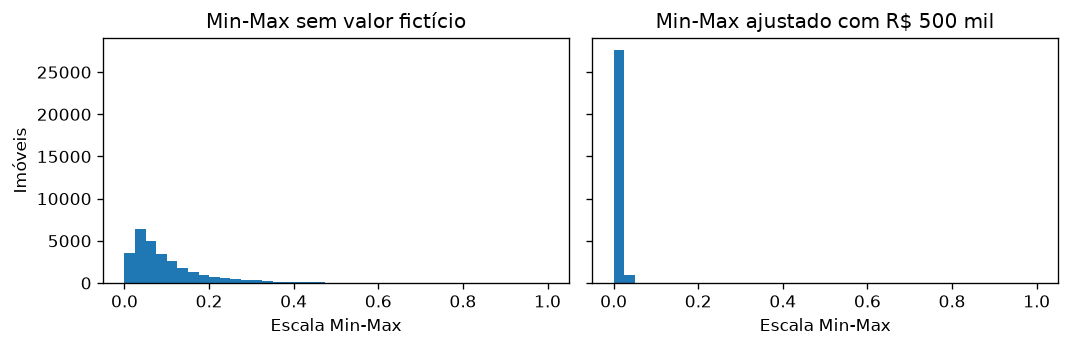

In [ ]:
alugueis = gabarito["rent_amount"].to_numpy()
coluna_aluguel = alugueis.reshape(-1, 1)
versoes = {"Original": alugueis}
for escalador in (StandardScaler(), RobustScaler(), MinMaxScaler()):
    versoes[type(escalador).__name__] = escalador.fit_transform(coluna_aluguel).ravel()

versoes["Log"] = np.log(alugueis)
versoes["Box-Cox"], lambda_boxcox = stats.boxcox(alugueis)
display(pd.Series({nome: stats.skew(valores) for nome, valores in versoes.items()},
                  name="Assimetria").round(4).to_frame())

com_extremo = np.append(alugueis, 500_000).reshape(-1, 1)
minmax_com_extremo = MinMaxScaler().fit_transform(com_extremo).ravel()[:-1]
fig, eixos = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for eixo, valores, titulo in zip(
    eixos, [versoes["MinMaxScaler"], minmax_com_extremo],
    ["Min-Max sem valor fictício", "Min-Max ajustado com R$ 500 mil"],
):
    eixo.hist(valores, bins=40, range=(0, 1))
    eixo.set(title=titulo, xlabel="Escala Min-Max")
eixos[0].set_ylabel("Imóveis")
plt.tight_layout()
plt.show()

## 4. Aplicar o pré-processamento à base

Registro as lacunas de condomínio e vagas antes de preencher pela mediana do grupo de tipo e padrão do imóvel. A mediana global é a alternativa para grupos sem observações. Depois, aplico log nas quatro variáveis positivas do exemplo e Yeo-Johnson a distância ao transporte, que pode ter zeros. Em um projeto de modelagem, os parâmetros dessas operações são estimados apenas no treino e reaplicados ao teste.

In [7]:
tratados = dados.copy()
for coluna in ("hoa", "parking_spaces"):
    tratados[f"{coluna}_missing"] = dados[coluna].isna()
    tratados[coluna] = mediana_por_grupo(dados, coluna, ["property_type", "tier"])

for coluna in ("area", "rent_amount", "property_tax", "total"):
    tratados[coluna] = np.log(dados[coluna])

distancia = "transit_distance_min"
tratados[distancia], lambda_distancia = stats.yeojohnson(dados[distancia])

display(pd.DataFrame({
    "Valores imputados": tratados[["hoa_missing", "parking_spaces_missing"]].sum().to_numpy(),
    "Lacunas restantes": tratados[["hoa", "parking_spaces"]].isna().sum(),
}))
colunas = ["area", "rent_amount", "property_tax", "total", distancia]
display(pd.DataFrame({
    "Antes": dados[colunas].apply(stats.skew),
    "Depois": tratados[colunas].apply(stats.skew),
}).round(4))

,Valores imputados,Lacunas restantes
hoa,505,0
parking_spaces,297,0


,Antes,Depois
area,1.5944,0.0898
rent_amount,2.2630,0.0442
property_tax,2.1620,0.0433
total,2.1726,0.1015
transit_distance_min,2.0917,-0.0769


## Para casa

### 1. Média e mediana para o número de quartos

Comparo as duas estratégias nas mesmas lacunas simuladas antes. Como o número de quartos é discreto, uma estimativa fracionária pode ser diferente e não comparável com a unidade de contagem. A mediana minimiza a soma dos erros absolutos entre as estimativas constantes, enquanto a média minimiza a soma dos erros quadráticos.

In [ ]:
quartos = simulado["rooms"]
resumo_quartos = pd.DataFrame({
    "Valor imputado": {"Média": quartos.mean(), "Mediana": quartos.median()},
})
resumo_quartos["MAE (quartos)"] = [
    mae_nas_lacunas("rooms", quartos.fillna(valor))
    for valor in resumo_quartos["Valor imputado"]
]
display(resumo_quartos.round(4))
print(f"Assimetria dos quartos observados: {stats.skew(quartos.dropna()):.4f}")

Assimetria dos quartos observados: 0.3777


,Valor imputado,MAE (quartos)
Média,2.2621,0.9913
Mediana,2.0000,0.9321


**Resposta**: Apaguei 2.783 valores de quartos. A média imputou 2,2621 quartos e teve MAE de 0,9913 quarto. A mediana imputou 2 quartos e teve MAE de 0,9321 quarto.

A assimetria positiva (0,3777) indica uma cauda à direita, e a média ficou acima da mediana. A mediana teve menor erro absoluto médio nesse teste e produziu uma contagem inteira, adequada ao caráter discreto da variável.

### 2. Aluguel por `tier` e zona, e depois por bairro

As duas estratégias preenchem as mesmas lacunas do aluguel. Comparo o MAE e a quantidade de aluguéis observados por grupo. Um bairro com poucos anúncios observados pode produzir uma mediana instável. Se o grupo não tiver nenhum aluguel observado, uso a mediana global.

In [ ]:
COLUNA_ZONA = next((c for c in ("zone", "zona") if c in simulado.columns), "zone")
COLUNA_BAIRRO = next(
    (c for c in ("neighborhood", "neighbourhood", "bairro", "district") if c in simulado.columns),
    "neighborhood",
)
for coluna in (COLUNA_ZONA, COLUNA_BAIRRO):
    if coluna not in simulado.columns:
        raise KeyError(f"Ajuste COLUNA_ZONA ou COLUNA_BAIRRO. Colunas: {simulado.columns.tolist()}")

linhas = {}
for nome, grupos in {
    "Tier e zona": ["tier", COLUNA_ZONA],
    "Bairro": [COLUNA_BAIRRO],
}.items():
    estimativas = mediana_por_grupo(simulado, "rent_amount", grupos)
    agrupado = simulado.groupby(grupos)["rent_amount"]
    observados_por_grupo = agrupado.count()
    observados_por_lacuna = agrupado.transform("count")[aluguel.isna()]
    linhas[nome] = {
        "MAE (R$)": mae_nas_lacunas("rent_amount", estimativas),
        "Grupos": len(observados_por_grupo),
        "Mediana de observações por grupo": observados_por_grupo.median(),
        "Mínimo de observações por grupo": observados_por_grupo.min(),
        "Lacunas com mediana global": int(observados_por_lacuna.fillna(0).eq(0).sum()),
    }

display(pd.DataFrame.from_dict(linhas, orient="index").round(2))

,MAE (R$),Grupos,Mediana de observações por grupo,Mínimo de observações por grupo,Lacunas com mediana global
Tier e zona,1800.94,16,1574.0,307,0
Bairro,1748.06,85,285.0,238,0


**Resposta**: Nas mesmas 4.308 lacunas simuladas, a mediana por `tier` e zona teve MAE de `R$ 1.800,94`. A mediana por bairro teve MAE de R$ 1.748,06, uma redução de `R$ 52,88`.

O agrupamento por bairro gerou 85 grupos, com mediana de 285 aluguéis observados por bairro e mínimo de 238. Por `tier` e zona, foram 16 grupos, com mediana de 1.574 observações e mínimo de 307. O bairro produziu grupos menores e teve menor erro neste teste. Se um bairro tivesse poucos aluguéis observados, sua mediana poderia variar mais. Nesta execução, todos os grupos usados na imputação tinham observações.

### 3. Transformações do condomínio entre apartamentos

Usei os valores observados de `hoa` nos apartamentos. Se houver valores iguais a zero, comparo as três técnicas no mesmo subconjunto positivo, pois Box-Cox exige valores estritamente positivos. Assim, também mostro os resultados das técnicas compatíveis com a base completa. Menor assimetria significa o valor mais próximo de zero.

In [ ]:
hoa = dados.loc[dados["property_type"].eq("apartamento"), "hoa"].dropna()
hoa_positivo = hoa[hoa.gt(0)]
print(f"Condomínios observados: {len(hoa)} | Zeros: {hoa.eq(0).sum()} | Negativos: {hoa.lt(0).sum()}")

boxcox_hoa, lambda_hoa = stats.boxcox(hoa_positivo)
yeojohnson_hoa, _ = stats.yeojohnson(hoa_positivo)
comparacao = pd.Series({
    "log1p": stats.skew(np.log1p(hoa_positivo)),
    "Box-Cox": stats.skew(boxcox_hoa),
    "Yeo-Johnson": stats.skew(yeojohnson_hoa),
}, name="Assimetria no conjunto positivo")
display(comparacao.to_frame().assign(**{"Assimetria absoluta": comparacao.abs()}).round(4))
print("Menor assimetria absoluta no conjunto positivo:", comparacao.abs().idxmin())

if len(hoa) != len(hoa_positivo):
    yeojohnson_todos, _ = stats.yeojohnson(hoa)
    todos = {"Yeo-Johnson": stats.skew(yeojohnson_todos)}
    if hoa.ge(0).all():
        todos["log1p"] = stats.skew(np.log1p(hoa))
    display(pd.Series(todos, name="Assimetria com todos os valores observados").round(4).to_frame())

Condomínios observados: 24519 | Zeros: 0 | Negativos: 0
Menor assimetria absoluta no conjunto positivo: Box-Cox


,Assimetria no conjunto positivo,Assimetria absoluta
log1p,0.1492,0.1492
Box-Cox,0.0004,0.0004
Yeo-Johnson,0.0005,0.0005


**Resposta**: Os 24.519 valores observados de condomínio dos apartamentos eram positivos, então comparei as três técnicas sobre os mesmos registros. A assimetria caiu de 2,127696 na escala original para 0,149205 com `log1p`, 0,000432 com Box-Cox e 0,000461 com Yeo-Johnson. Box-Cox ficou mais perto de zero, por uma diferença pequena em relação a Yeo-Johnson.

Para um gestor, apresentaria o condomínio em reais, que permite interpretar os valores diretamente. Se precisasse mostrar uma das escalas transformadas, escolheria `log1p`, pois reduz bastante a assimetria nesta base e permite voltar à escala original com `expm1`.